Dataset shape: (7043, 21)
Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

First 5 rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1          

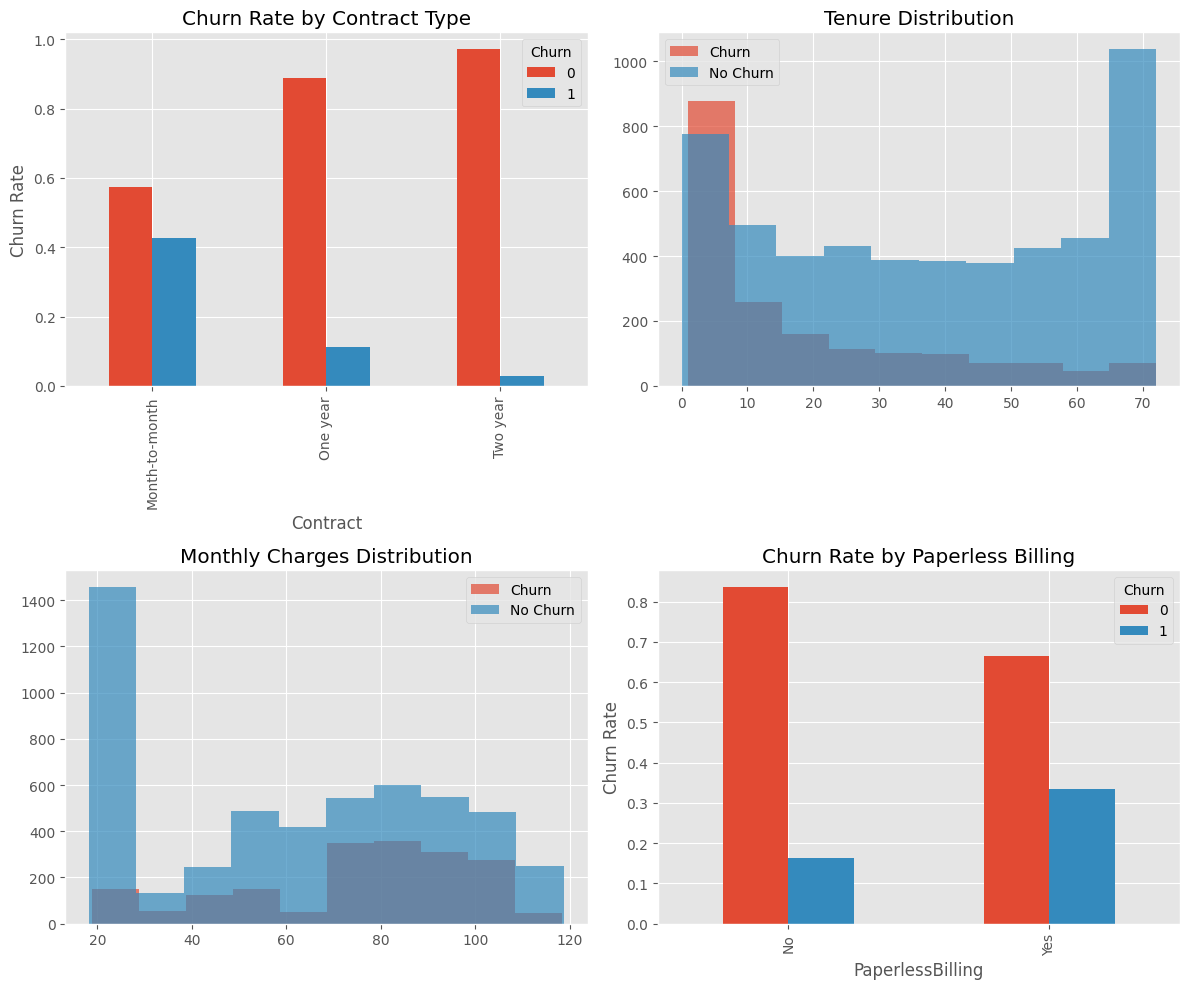


Train size: 5634, Test size: 1409

MODEL PERFORMANCE COMPARISON
              Model  Train Acc  Test Acc  Precision  Recall  F1-Score  ROC-AUC  CV Mean  CV Std
Logistic Regression     0.8055    0.8055     0.6572  0.5588    0.6040   0.8421   0.8042  0.0142
      Random Forest     0.9980    0.7857     0.6216  0.4920    0.5493   0.8244   0.7890  0.0142

BEST MODEL: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


Confusion Matrix:
[[926 109]
 [165 209]]


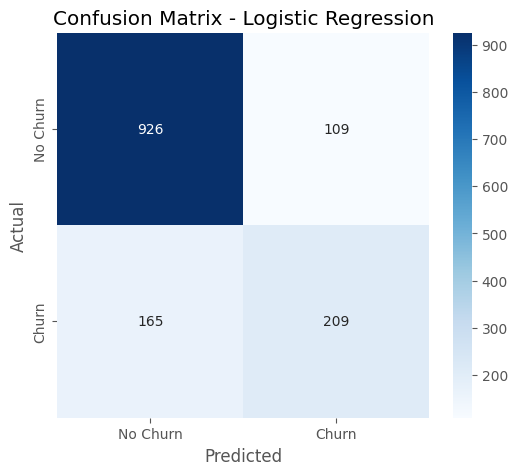


BUSINESS INSIGHTS

1. Month-to-month contract churn rate: 42.7%
   Two year contract churn rate: 2.8%
   → Offer incentives for long-term contracts

2. Avg tenure of churned customers: 18.0 months
   Avg tenure of loyal customers: 37.6 months
   → Focus retention on new customers (first year)

3. Paperless billing churn rate: 33.6%
   Traditional billing churn rate: 16.3%
   → Improve digital customer experience

PROJECT COMPLETED


In [2]:
# ==================================================
# Customer Churn Prediction - Simple ML Project
# Dataset: Telco Customer Churn
# ==================================================

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             roc_auc_score)

# 2. Load Data
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nFirst 5 rows:")
print(df.head())

# 3. Data Cleaning
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
df = df.drop(columns=['customerID'])
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

# 4. Exploratory Data Analysis
print("\nChurn Distribution:")
print(df['Churn'].value_counts())
print(f"Churn rate: {df['Churn'].mean()*100:.2f}%")

# Quick visualizations
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Churn by Contract
pd.crosstab(df['Contract'], df['Churn'], normalize='index').plot(kind='bar', ax=axes[0,0])
axes[0,0].set_title('Churn Rate by Contract Type')
axes[0,0].set_ylabel('Churn Rate')

# Churn by Tenure
df[df['Churn']==1]['tenure'].hist(alpha=0.7, label='Churn', ax=axes[0,1])
df[df['Churn']==0]['tenure'].hist(alpha=0.7, label='No Churn', ax=axes[0,1])
axes[0,1].set_title('Tenure Distribution')
axes[0,1].legend()

# Churn by MonthlyCharges
df[df['Churn']==1]['MonthlyCharges'].hist(alpha=0.7, label='Churn', ax=axes[1,0])
df[df['Churn']==0]['MonthlyCharges'].hist(alpha=0.7, label='No Churn', ax=axes[1,0])
axes[1,0].set_title('Monthly Charges Distribution')
axes[1,0].legend()

# Churn by PaperlessBilling
pd.crosstab(df['PaperlessBilling'], df['Churn'], normalize='index').plot(kind='bar', ax=axes[1,1])
axes[1,1].set_title('Churn Rate by Paperless Billing')
axes[1,1].set_ylabel('Churn Rate')

plt.tight_layout()
plt.show()

# 5. Prepare Data for Modeling
numerical_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
                        'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
                        'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
                        'Contract', 'PaperlessBilling', 'PaymentMethod']

X = df.drop(columns=['Churn'])
y = df['Churn']

# 6. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"\nTrain size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")

# 7. Preprocessing Pipeline
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# 8. Create and Train Models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    pipeline.fit(X_train, y_train)

    y_train_pred = pipeline.predict(X_train)
    y_test_pred = pipeline.predict(X_test)
    y_test_proba = pipeline.predict_proba(X_test)[:, 1]

    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='accuracy')

    results.append({
        'Model': name,
        'Train Acc': accuracy_score(y_train, y_train_pred),
        'Test Acc': accuracy_score(y_test, y_test_pred),
        'Precision': precision_score(y_test, y_test_pred),
        'Recall': recall_score(y_test, y_test_pred),
        'F1-Score': f1_score(y_test, y_test_pred),
        'ROC-AUC': roc_auc_score(y_test, y_test_proba),
        'CV Mean': cv_scores.mean(),
        'CV Std': cv_scores.std()
    })

# 9. Results
results_df = pd.DataFrame(results)
print("\n" + "="*60)
print("MODEL PERFORMANCE COMPARISON")
print("="*60)
print(results_df.round(4).to_string(index=False))

# 10. Best Model Detailed Report
best_model_name = results_df.loc[results_df['F1-Score'].idxmax(), 'Model']
best_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                                ('classifier', models[best_model_name])])
best_pipeline.fit(X_train, y_train)
y_pred = best_pipeline.predict(X_test)
y_proba = best_pipeline.predict_proba(X_test)[:, 1]

print(f"\n" + "="*60)
print(f"BEST MODEL: {best_model_name}")
print("="*60)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Feature Importance for Random Forest
if best_model_name == 'Random Forest':
    preprocessor.fit(X_train)
    num_features = numerical_features
    cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
    cat_features = cat_encoder.get_feature_names_out(categorical_features)
    all_features = list(num_features) + list(cat_features)

    feature_importance = best_pipeline.named_steps['classifier'].feature_importances_
    importance_df = pd.DataFrame({'Feature': all_features[:len(feature_importance)],
                                  'Importance': feature_importance})
    importance_df = importance_df.sort_values('Importance', ascending=False).head(10)

    print("\nTop 10 Most Important Features:")
    print(importance_df.to_string(index=False))

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df['Feature'], importance_df['Importance'], color='teal')
    plt.xlabel('Importance')
    plt.title(f'Top 10 Feature Importances - {best_model_name}')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

# 11. Business Insights
print("\n" + "="*60)
print("BUSINESS INSIGHTS")
print("="*60)

contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
print(f"\n1. Month-to-month contract churn rate: {contract_churn.loc['Month-to-month', 1]:.1f}%")
print(f"   Two year contract churn rate: {contract_churn.loc['Two year', 1]:.1f}%")
print("   → Offer incentives for long-term contracts")

tenure_churn = df[df['Churn']==1]['tenure'].mean()
tenure_loyal = df[df['Churn']==0]['tenure'].mean()
print(f"\n2. Avg tenure of churned customers: {tenure_churn:.1f} months")
print(f"   Avg tenure of loyal customers: {tenure_loyal:.1f} months")
print("   → Focus retention on new customers (first year)")

paperless_churn = pd.crosstab(df['PaperlessBilling'], df['Churn'], normalize='index') * 100
print(f"\n3. Paperless billing churn rate: {paperless_churn.loc['Yes', 1]:.1f}%")
print(f"   Traditional billing churn rate: {paperless_churn.loc['No', 1]:.1f}%")
print("   → Improve digital customer experience")

print("\n" + "="*60)
print("PROJECT COMPLETED")
print("="*60)
